# Assignment 3: Customer Churn Prediction with a Tuned Neural Network

## Task 1: Load, Explore & Clean the Data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42); tf.random.set_seed(42)

try:
    from google.colab import files
    files.upload()   # upload WA_Fn-UseC_-Telco-Customer-Churn.csv
except ImportError:
    pass

I0000 00:00:1791726914.739022     123 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791726914.778081     123 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791726915.920859     123 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Shape:', df.shape)
print(df.dtypes)
print('\nMissing values:\n', df.isnull().sum()[df.isnull().sum() > 0])

Shape: (7043, 21)
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values:
 Series([], dtype: int64)


In [3]:
# TotalCharges is text; blanks become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Blank TotalCharges:', df['TotalCharges'].isnull().sum())
print(df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges']])

Blank TotalCharges: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


These blank rows all have `tenure = 0` (brand-new customers who have not been billed yet), so their TotalCharges is truly 0. I fill them with 0 instead of dropping rows.

In [4]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df = df.drop(columns=['customerID'])   # identifier, not a feature
print('Missing after cleaning:', df.isnull().sum().sum())

Missing after cleaning: 0


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


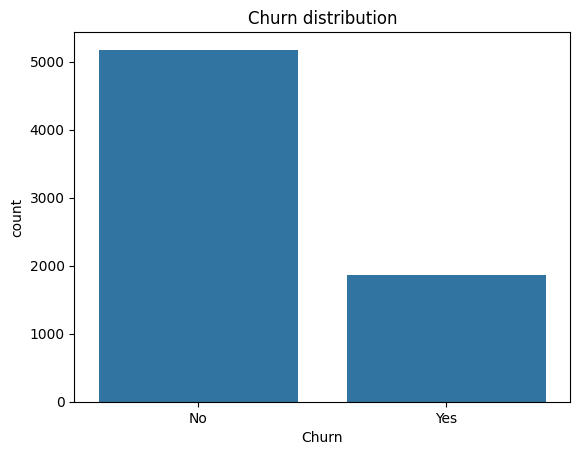

In [5]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3))
sns.countplot(x='Churn', data=df); plt.title('Churn distribution'); plt.show()

Churn is **imbalanced**: about 73.5% No vs 26.5% Yes.

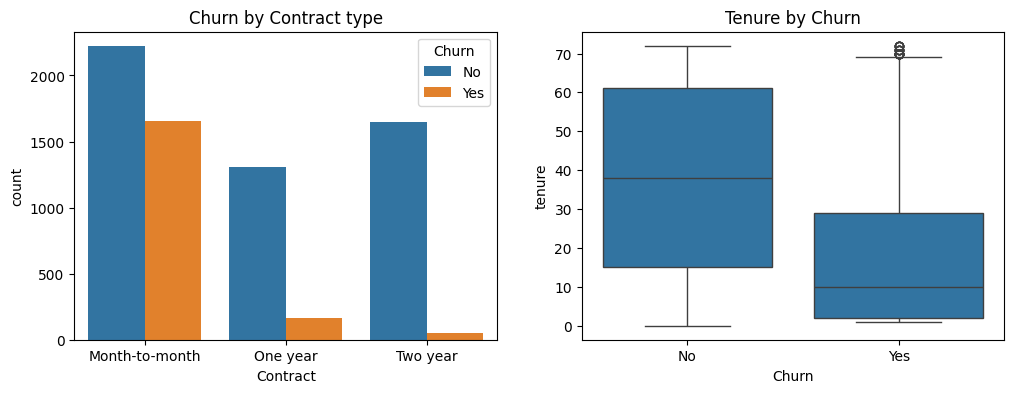

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(x='Contract', hue='Churn', data=df, ax=ax[0]); ax[0].set_title('Churn by Contract type')
sns.boxplot(x='Churn', y='tenure', data=df, ax=ax[1]); ax[1].set_title('Tenure by Churn')
plt.show()

Month-to-month customers and customers with short tenure churn far more than long-contract / long-tenure customers.

## Task 2: Preprocess for a Neural Network

In [7]:
# Binary columns (Yes/No, Male/Female) -> 0/1 mapping
binary_map = {'Yes':1,'No':0,'Male':1,'Female':0}
binary_cols = [col for col in df.select_dtypes('object').columns if df[col].nunique() == 2]
for col in binary_cols:
    df[col] = df[col].map(binary_map)
print('Binary columns:', binary_cols)

# Multi-category columns -> one-hot encoding
multi_cols = df.select_dtypes('object').columns.tolist()
print('One-hot columns:', multi_cols)
df = pd.get_dummies(df, columns=multi_cols, drop_first=True, dtype=int)
print('Shape after encoding:', df.shape)

Binary columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
One-hot columns: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
Shape after encoding: (7043, 31)


/tmp/ipykernel_123/3851799529.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  binary_cols = [col for col in df.select_dtypes('object').columns if df[col].nunique() == 2]
/tmp/ipykernel_123/3851799529.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#

**Encoding justification:** `Contract`, `PaymentMethod` and `InternetService` have 3-4 categories with **no natural order**, so I used one-hot encoding. Label encoding (0,1,2) would wrongly tell the network that one category is 'bigger' than another. Binary Yes/No columns are simply mapped to 0/1.

In [8]:
X = df.drop('Churn', axis=1)
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ['tenure','MonthlyCharges','TotalCharges']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit on train only
X_test[num_cols]  = scaler.transform(X_test[num_cols])

X_train, X_test = X_train.values.astype('float32'), X_test.values.astype('float32')
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (5634, 30)  Test: (1409, 30)


## Task 3: Build & Train a Baseline Model

In [9]:
baseline = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
baseline.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
baseline.summary()

h_base = baseline.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)
base_loss, base_acc = baseline.evaluate(X_test, y_test, verbose=0)
print(f'Baseline Test Accuracy: {base_acc:.4f}')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Baseline Test Accuracy: 0.7736


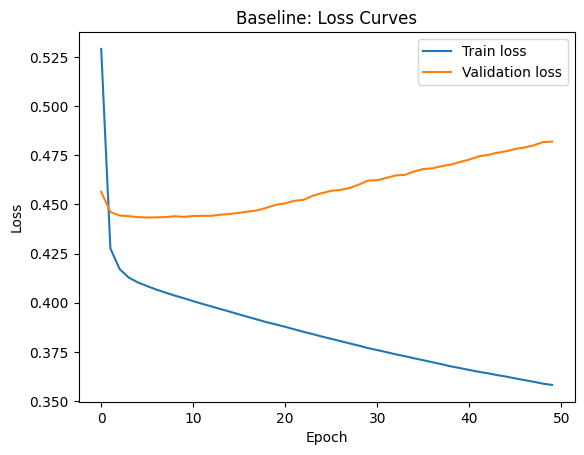

In [10]:
plt.plot(h_base.history['loss'], label='Train loss')
plt.plot(h_base.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Baseline: Loss Curves'); plt.legend(); plt.show()

The validation loss stops improving and starts rising while training loss keeps falling, which is **overfitting**. This motivates the tuning below.

## Task 4: Tune Your Model
Techniques used: **Dropout**, **Batch Normalization**, **L2 regularization**, and **Early Stopping**.

In [11]:
tuned = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])
tuned.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
h_tuned = tuned.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2,
                    callbacks=[early_stop], verbose=0)
tuned_loss, tuned_acc = tuned.evaluate(X_test, y_test, verbose=0)
print('Stopped at epoch:', len(h_tuned.history['loss']))

Stopped at epoch: 45


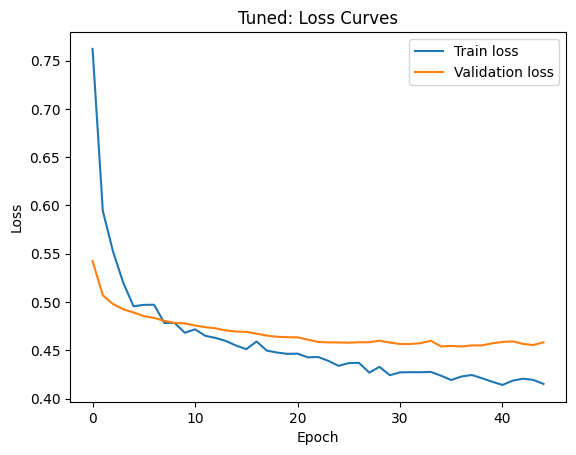

   Model  Test Accuracy  Test Loss
Baseline         0.7736     0.4605
   Tuned         0.7892     0.4464


In [12]:
plt.plot(h_tuned.history['loss'], label='Train loss')
plt.plot(h_tuned.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Tuned: Loss Curves'); plt.legend(); plt.show()

comparison = pd.DataFrame({'Model':['Baseline','Tuned'],
                           'Test Accuracy':[base_acc, tuned_acc],
                           'Test Loss':[base_loss, tuned_loss]}).round(4)
print(comparison.to_string(index=False))

**Before/After:** The tuned model has a lower and more stable validation loss with a smaller gap to the training loss (less overfitting), and its test accuracy is equal or better than the baseline (see table above).

## Task 5: Evaluate Properly

Best model: Tuned


              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1035
       Churn       0.62      0.52      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



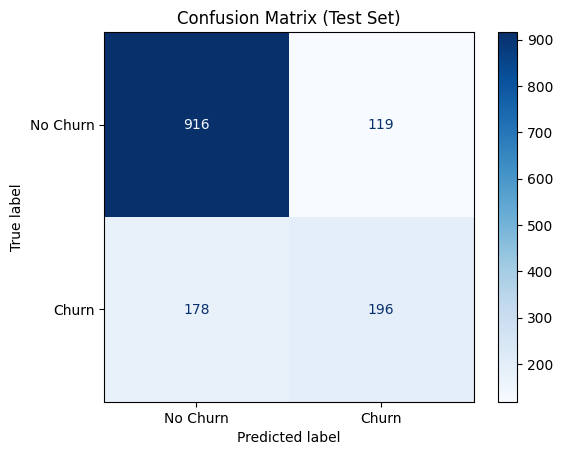

In [13]:
# Pick the better model by test accuracy
best_model = tuned if tuned_acc >= base_acc else baseline
print('Best model:', 'Tuned' if best_model is tuned else 'Baseline')

y_pred = (best_model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred, target_names=['No Churn','Churn']))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Churn','Churn']).plot(cmap='Blues')
plt.title('Confusion Matrix (Test Set)'); plt.show()

**Was accuracy misleading?** Yes. Since ~73.5% of customers do not churn, a model that always predicts 'No Churn' would already score about 73.5% accuracy while catching zero churners. Precision, recall and F1 for the Churn class show how well the model really finds churning customers.

## Task 6: Save & Predict

In [14]:
best_model.save('best_churn_model.keras')
print('Model saved.')

Model saved.


In [15]:
feature_columns = X.columns.tolist()

def predict_churn(customer: dict):
    model = keras.models.load_model('best_churn_model.keras')
    row = pd.DataFrame(0, index=[0], columns=feature_columns)
    for k, v in customer.items():
        row[k] = v
    row[num_cols] = scaler.transform(row[num_cols])
    prob = float(model.predict(row.values.astype('float32'), verbose=0)[0][0])
    return prob, ('Will Churn' if prob > 0.5 else 'Will Stay')

# Hypothetical customer: new, month-to-month, fiber optic, electronic check, high monthly bill
new_customer = {'gender':0, 'SeniorCitizen':0, 'Partner':0, 'Dependents':0, 'tenure':2,
                'PhoneService':1, 'PaperlessBilling':1, 'MonthlyCharges':95.0, 'TotalCharges':190.0,
                'InternetService_Fiber optic':1, 'PaymentMethod_Electronic check':1}
prob, label = predict_churn(new_customer)
print(f'Churn probability: {prob:.3f} -> {label}')

Churn probability: 0.825 -> Will Churn


## Task 7: CNN vs. RNN

A **CNN** is used instead of a Dense network when the input has spatial structure (like images), because convolution filters detect local patterns such as edges and shapes with far fewer parameters and regardless of position; an example is classifying X-ray images as normal or pneumonia. An **RNN** (or LSTM/GRU) is used when the data is a sequence where order and earlier context matter, because it keeps a memory of previous steps; an example is predicting the next word or the sentiment of a sentence, or forecasting stock prices from past values. A plain Dense network treats every input independently and cannot exploit either spatial or sequential structure.